<a href="https://colab.research.google.com/github/davidcechak/DL-for-bio-course/blob/master/06_ECG_heartbeats_RNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# SOLVED - Heartbeat classification with recurrent neural networks

In Notebook 04 we classified DNA with an MLP and a CNN. Now we use **recurrent neural networks (RNNs)** on a different kind of sequence: an **electrocardiogram (ECG)**, the electrical signal of the heart.

**ECG5000** contains 5,000 heartbeats. Each beat is cut out of a long ECG recording and resampled to **140 time points**. The task: given one heartbeat, predict its class.

| class | name | what it means |
|---|---|---|
| 0 | Normal | normal heartbeat |
| 1 | R-on-T PVC | premature ventricular contraction that lands on the T wave of the previous beat |
| 2 | PVC | premature ventricular contraction |
| 3 | SP or EB | supraventricular premature or ectopic beat |
| 4 | Unclassified | unclassified beat |

All beats come from **one 20-hour ECG of one patient** with severe congestive heart failure (record chf07, BIDMC Congestive Heart Failure Database, PhysioNet). Keep this in mind when you look at the results.

## Setup
Optional: switch to a GPU runtime (Runtime -> Change runtime type -> T4 GPU). The dataset is small, so everything also runs on a CPU in a few minutes.

In [ ]:
!pip install torchmetrics -q

In [2]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Using', device)

Using cpu


# Data download and preparation
We download the official train/test split of the UCR time series archive (a copy hosted by the sktime project on Hugging Face). The files use the `.ts` format: header lines start with `@` or `#`, then one beat per line: `value1,value2,...,value140:class`.

In [3]:
import requests

BASE_URL = 'https://huggingface.co/datasets/sktime/tsc-datasets/resolve/main/ECG5000/'

def load_ts(url):
    text = requests.get(url).text
    X, y = [], []
    for line in text.splitlines():
        line = line.strip()
        if not line or line.startswith(('#', '@')):   # skip header lines
            continue
        values, label = line.rsplit(':', 1)
        X.append([float(v) for v in values.split(',')])
        y.append(int(label) - 1)                      # classes 1..5 -> 0..4
    return np.array(X, dtype=np.float32), np.array(y)

X_train, y_train = load_ts(BASE_URL + 'ECG5000_TRAIN.ts')
X_test, y_test = load_ts(BASE_URL + 'ECG5000_TEST.ts')

print(X_train.shape, y_train.shape)
print(X_test.shape, y_test.shape)

(500, 140) (500,)
(4500, 140) (4500,)


## Data exploration

In [4]:
class_names = ['Normal', 'R-on-T PVC', 'PVC', 'SP or EB', 'Unclassified']

for c, name in enumerate(class_names):
    print(f'{c} {name:13s} train: {np.sum(y_train == c):4d}   test: {np.sum(y_test == c):4d}')

0 Normal        train:  292   test: 2627
1 R-on-T PVC    train:  177   test: 1590
2 PVC           train:   10   test:   86
3 SP or EB      train:   19   test:  175
4 Unclassified  train:    2   test:   22


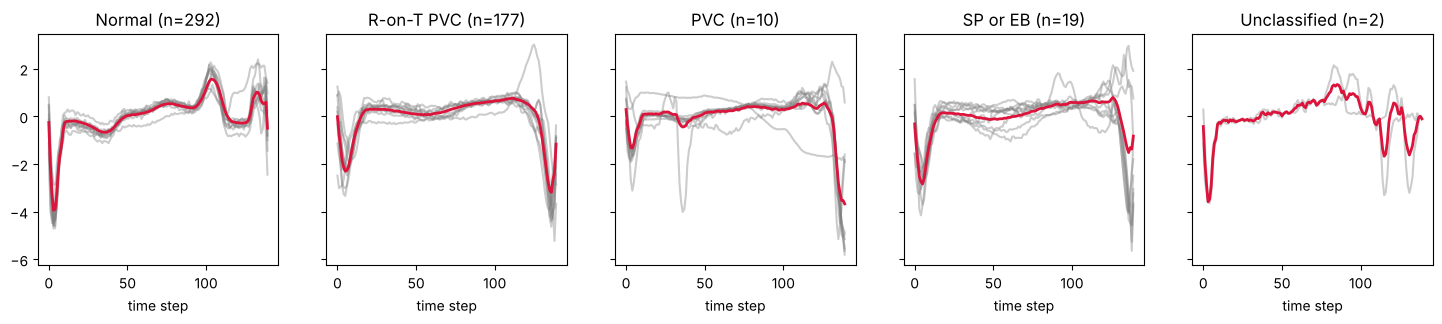

In [5]:
fig, axes = plt.subplots(1, 5, figsize=(18, 3), sharey=True)
for c, ax in enumerate(axes):
    for beat in X_train[y_train == c][:10]:
        ax.plot(beat, color='grey', alpha=0.4)
    ax.plot(X_train[y_train == c].mean(axis=0), color='crimson', linewidth=2)   # average beat of the class
    ax.set_title(f'{class_names[c]} (n={np.sum(y_train == c)})')
    ax.set_xlabel('time step')
plt.show()

**Quiz**
1. A lazy model always answers "Normal". What test accuracy does it get?
2. Why is accuracy alone a bad metric for this dataset?

In [6]:
# Quiz 1 - accuracy of always predicting "Normal"
np.mean(y_test == 0)

np.float64(0.5837777777777777)

# Feeding a signal into an RNN
An RNN reads the beat **one time step at a time** and updates its hidden state (its memory) after every step.

PyTorch expects the input shape `(batch, time steps, features per step)`. One beat has 140 time steps and 1 feature per step (the voltage). With `batch_first=True` the batch dimension comes first.

In [7]:
beat = torch.tensor(X_train[0])     # (140,)
x = beat.reshape(1, 140, 1)          # (batch=1, time=140, features=1)

rnn = nn.RNN(input_size=1, hidden_size=8, batch_first=True)
output, h_n = rnn(x)

print('output:', output.shape)   # hidden state after EVERY time step -> many-to-many
print('h_n:   ', h_n.shape)      # hidden state after the LAST time step -> many-to-one

output: torch.Size([1, 140, 8])
h_n:    torch.Size([1, 1, 8])


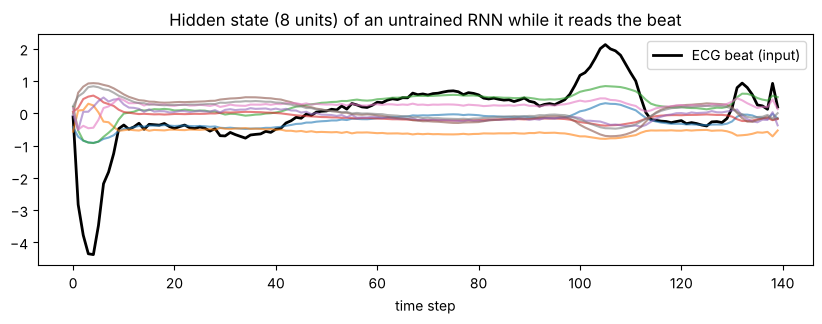

In [8]:
plt.figure(figsize=(10, 3))
plt.plot(beat, color='black', linewidth=2, label='ECG beat (input)')
plt.plot(output[0].detach(), alpha=0.6)
plt.title('Hidden state (8 units) of an untrained RNN while it reads the beat')
plt.xlabel('time step')
plt.legend()
plt.show()

In [9]:
# Quiz - how many parameters does this RNN have? (Hint: W_x, W_h and two bias vectors)
sum(p.numel() for p in rnn.parameters())

88

In [10]:
# Quiz - does the number of parameters change for a 1000-sample signal?
output_long, h_long = rnn(torch.randn(1, 1000, 1))
print(output_long.shape, h_long.shape)

torch.Size([1, 1000, 8]) torch.Size([1, 1, 8])


For classification we use the **last hidden state** `h_n`: the network reads the whole beat and then answers once (**many-to-one**).

## Pytorch dataset

In [11]:
from torch.utils.data import Dataset, DataLoader

class ECGDataset(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = y

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        x = torch.tensor(self.X[idx]).unsqueeze(-1)   # (140,) -> (140, 1) = (time steps, features)
        y = torch.tensor(self.y[idx])                 # class index 0..4
        return x, y

train_dset = ECGDataset(X_train, y_train)
test_dset = ECGDataset(X_test, y_test)

sample_x, sample_y = train_dset[0]
print(sample_x.shape, sample_y)

torch.Size([140, 1]) tensor(0)


# Training and evaluation
Five classes -> `CrossEntropyLoss` (it applies the softmax internally, so the model outputs raw scores).

Because the classes are imbalanced, we report **macro F1** next to accuracy: the F1 score is computed for each class separately and then averaged, so the rare classes count as much as "Normal".

In [12]:
def train(model, dataset, batch_size=32, lr=1e-3, epochs=60):
    model.to(device)
    train_loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)
    loss_function = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    for epoch in range(epochs):
        model.train()
        batch_losses = []
        for batch_x, batch_y in train_loader:
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)
            outputs = model(batch_x)
            loss = loss_function(outputs, batch_y)
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()
            batch_losses.append(loss.item())
        if (epoch + 1) % 10 == 0:
            print(f'Epoch {epoch + 1}: mean loss {np.mean(batch_losses):.3f}')

In [13]:
import pandas as pd
from torchmetrics.classification import MulticlassAccuracy, MulticlassF1Score, MulticlassConfusionMatrix

def evaluate(model, dataset, show_confusion=False):
    model.to(device)
    model.eval()   # turn off training-only layers
    loader = DataLoader(dataset, batch_size=256, shuffle=False)
    predictions, labels = [], []
    with torch.no_grad():   # don't track gradients
        for batch_x, batch_y in loader:
            predictions.append(model(batch_x.to(device)).cpu())
            labels.append(batch_y)
    predictions, labels = torch.cat(predictions), torch.cat(labels)

    accuracy = MulticlassAccuracy(num_classes=5, average='micro')(predictions, labels).item()
    macro_f1 = MulticlassF1Score(num_classes=5, average='macro')(predictions, labels).item()
    print(f'Accuracy: {accuracy:.3f}   Macro F1: {macro_f1:.3f}')

    if show_confusion:
        cm = MulticlassConfusionMatrix(num_classes=5)(predictions, labels).numpy()
        display(pd.DataFrame(cm, index=['true: ' + n for n in class_names], columns=['pred: ' + n for n in class_names]))
    return accuracy, macro_f1

results = {}

## Baseline: MLP
Every beat has exactly 140 samples, so the MLP from Notebooks 02 and 04 works here too. It is the number to beat.

In [14]:
class MLP(nn.Module):
    def __init__(self, length=140, hidden_size=64, num_classes=5):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),                      # (batch, 140, 1) -> (batch, 140)
            nn.Linear(length, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, num_classes),
        )

    def forward(self, x):
        return self.net(x)

torch.manual_seed(0)
mlp_model = MLP()
train(mlp_model, train_dset)
results['MLP'] = evaluate(mlp_model, test_dset, show_confusion=True)

Epoch 10: mean loss 0.160
Epoch 20: mean loss 0.110


Epoch 30: mean loss 0.086
Epoch 40: mean loss 0.073


Epoch 50: mean loss 0.058
Epoch 60: mean loss 0.053


Accuracy: 0.938   Macro F1: 0.589


,pred: Normal,pred: R-on-T PVC,pred: PVC,pred: SP or EB,pred: Unclassified
true: Normal,2617,6,2,1,1
true: R-on-T PVC,31,1493,13,53,0
true: PVC,26,23,31,5,1
true: SP or EB,8,84,4,79,0
true: Unclassified,11,6,4,0,1


# Exercise 1: vanilla RNN
Build a **many-to-one** RNN classifier:
1. `nn.RNN(input_size=1, hidden_size=hidden_size, batch_first=True)`
2. take the last hidden state `h_n` - its shape is `(num_layers, batch, hidden_size)`, so use `h_n[-1]`
3. `nn.Linear(hidden_size, num_classes)` turns it into 5 class scores

Tips
* Use the PyTorch documentation of [nn.RNN](https://pytorch.org/docs/stable/generated/torch.nn.RNN.html)
* `nn.RNN` returns two things: `output, h_n = self.rnn(x)`

In [15]:
class RNNClassifier(nn.Module):
    def __init__(self, hidden_size=64, num_classes=5):
        super().__init__()
        self.rnn = nn.RNN(input_size=1, hidden_size=hidden_size, batch_first=True)
        self.head = nn.Linear(hidden_size, num_classes)

    def forward(self, x):
        output, h_n = self.rnn(x)    # h_n: (1, batch, hidden_size)
        return self.head(h_n[-1])    # (batch, num_classes)

# Test the RNN
rnn_model = RNNClassifier()
sample_input = torch.rand(32, 140, 1)
rnn_model(sample_input).size()   # should be torch.Size([32, 5])

torch.Size([32, 5])

In [16]:
torch.manual_seed(0)
rnn_model = RNNClassifier()
train(rnn_model, train_dset)
results['RNN'] = evaluate(rnn_model, test_dset)

Epoch 10: mean loss 0.326


Epoch 20: mean loss 0.271


Epoch 30: mean loss 0.252


Epoch 40: mean loss 0.253


Epoch 50: mean loss 0.235


Epoch 60: mean loss 0.225


Accuracy: 0.924   Macro F1: 0.526


# Exercise 2: LSTM and GRU
Copy your RNN classifier and swap the recurrent layer:
* `nn.LSTM` returns **two** states: `output, (h_n, c_n) = self.lstm(x)` - `h_n` is the hidden state, `c_n` the cell state (the "long-term memory" line from the slides). Use `h_n`.
* `nn.GRU` has the same interface as `nn.RNN`.

Quiz - before you run it: which model has the most parameters? Check with `sum(p.numel() for p in model.parameters())`.

In [17]:
class LSTMClassifier(nn.Module):
    def __init__(self, hidden_size=64, num_classes=5):
        super().__init__()
        self.lstm = nn.LSTM(input_size=1, hidden_size=hidden_size, batch_first=True)
        self.head = nn.Linear(hidden_size, num_classes)

    def forward(self, x):
        output, (h_n, c_n) = self.lstm(x)   # LSTM: hidden state AND cell state
        return self.head(h_n[-1])


class GRUClassifier(nn.Module):
    def __init__(self, hidden_size=64, num_classes=5):
        super().__init__()
        self.gru = nn.GRU(input_size=1, hidden_size=hidden_size, batch_first=True)
        self.head = nn.Linear(hidden_size, num_classes)

    def forward(self, x):
        output, h_n = self.gru(x)
        return self.head(h_n[-1])

# Test the models
for model in [LSTMClassifier(), GRUClassifier()]:
    print(type(model).__name__, model(torch.rand(32, 140, 1)).size())

LSTMClassifier torch.Size([32, 5])
GRUClassifier torch.Size([32, 5])


In [18]:
for name, model in [('RNN', RNNClassifier()), ('LSTM', LSTMClassifier()), ('GRU', GRUClassifier())]:
    print(name, sum(p.numel() for p in model.parameters()), 'parameters')

RNN 4613 parameters
LSTM 17477 parameters
GRU 13189 parameters


In [19]:
torch.manual_seed(0)
lstm_model = LSTMClassifier()
train(lstm_model, train_dset)
results['LSTM'] = evaluate(lstm_model, test_dset)

torch.manual_seed(0)
gru_model = GRUClassifier()
train(gru_model, train_dset)
results['GRU'] = evaluate(gru_model, test_dset)

Epoch 10: mean loss 0.302


Epoch 20: mean loss 0.299


Epoch 30: mean loss 0.281


Epoch 40: mean loss 0.222


Epoch 50: mean loss 0.184


...

Epoch 30: mean loss 0.201


Epoch 40: mean loss 0.184


Epoch 50: mean loss 0.161


Epoch 60: mean loss 0.129


Accuracy: 0.935   Macro F1: 0.556


# Exercise 3: bidirectional LSTM
Add `bidirectional=True`. Now one LSTM reads the beat forward and a second one backward.
* `h_n` has shape `(2, batch, hidden_size)`: `h_n[-2]` is the last **forward** state, `h_n[-1]` the last **backward** state
* concatenate them with `torch.cat([..., ...], dim=1)` -> `2 * hidden_size` numbers -> adjust the input size of the `nn.Linear`

In [20]:
class BiLSTMClassifier(nn.Module):
    def __init__(self, hidden_size=64, num_classes=5):
        super().__init__()
        self.lstm = nn.LSTM(input_size=1, hidden_size=hidden_size, batch_first=True, bidirectional=True)
        self.head = nn.Linear(2 * hidden_size, num_classes)

    def forward(self, x):
        output, (h_n, c_n) = self.lstm(x)           # h_n: (2, batch, hidden_size)
        h = torch.cat([h_n[-2], h_n[-1]], dim=1)    # last forward + last backward state
        return self.head(h)

# Test the model
BiLSTMClassifier()(torch.rand(32, 140, 1)).size()   # should be torch.Size([32, 5])

torch.Size([32, 5])

In [21]:
torch.manual_seed(0)
bilstm_model = BiLSTMClassifier()
train(bilstm_model, train_dset)
results['BiLSTM'] = evaluate(bilstm_model, test_dset, show_confusion=True)

Epoch 10: mean loss 0.261


Epoch 20: mean loss 0.214


Epoch 30: mean loss 0.167


Epoch 40: mean loss 0.150


Epoch 50: mean loss 0.136


Epoch 60: mean loss 0.151


Accuracy: 0.935   Macro F1: 0.557


,pred: Normal,pred: R-on-T PVC,pred: PVC,pred: SP or EB,pred: Unclassified
true: Normal,2603,5,5,14,0
true: R-on-T PVC,37,1511,11,28,3
true: PVC,24,33,26,2,1
true: SP or EB,8,95,3,69,0
true: Unclassified,13,7,1,1,0


## Comparison

In [22]:
pd.DataFrame(results, index=['accuracy', 'macro F1']).T.round(3)

,accuracy,macro F1
MLP,0.938,0.589
RNN,0.924,0.526
LSTM,0.935,0.550
GRU,0.935,0.556
BiLSTM,0.935,0.557


**Questions**
1. Did any RNN clearly beat the MLP? Why not? (Hint: are all beats the same length? Are they aligned?)
2. Look at the confusion matrices. What happens to the classes with 10, 19 and 2 training examples?
3. Results change a bit between runs. Rerun one model with `torch.manual_seed(1)` - how big is the difference compared to the differences between models?

# Exercise 4: memory test - can the network remember?
In a heartbeat the useful information is spread over the whole beat, including its last samples. So even a network with a **short memory** does well.

Let's make memory necessary: after every beat we add **50 time steps of flat line** (silence). The network sees the beat, then 50 steps of nothing, and only then answers. It has to carry the information through 50 extra steps (slide "Backpropagation through time").

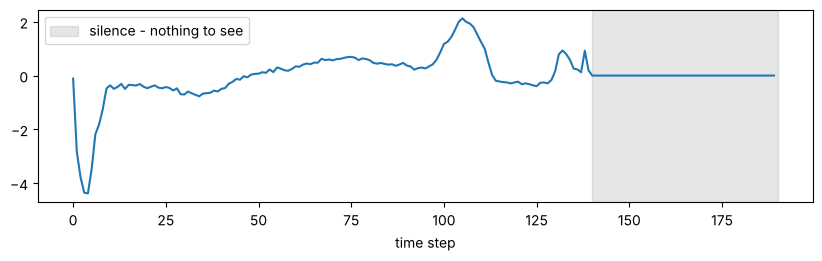

In [23]:
def add_silence(X, n_steps):
    # append n_steps of flat line (zeros) after every beat
    return np.concatenate([X, np.zeros((len(X), n_steps), dtype=np.float32)], axis=1)

SILENCE = 50
train_silence = ECGDataset(add_silence(X_train, SILENCE), y_train)
test_silence = ECGDataset(add_silence(X_test, SILENCE), y_test)

plt.figure(figsize=(10, 2.5))
plt.plot(train_silence[0][0].squeeze())
plt.axvspan(140, 140 + SILENCE, color='grey', alpha=0.2, label='silence - nothing to see')
plt.xlabel('time step')
plt.legend()
plt.show()

In [24]:
memory_results = {}
for name, model_class in [('RNN', RNNClassifier), ('LSTM', LSTMClassifier), ('GRU', GRUClassifier)]:
    print(name)
    torch.manual_seed(0)
    model = model_class()
    train(model, train_silence)
    memory_results[name] = evaluate(model, test_silence)

RNN


Epoch 10: mean loss 0.903


Epoch 20: mean loss 0.908


Epoch 30: mean loss 0.910


Epoch 40: mean loss 0.913


...

Epoch 30: mean loss 0.314


Epoch 40: mean loss 0.316


Epoch 50: mean loss 0.326


Epoch 60: mean loss 0.319


Accuracy: 0.917   Macro F1: 0.377


**Questions**
1. Which models fell back to always answering "Normal" (accuracy ~0.584, see the quiz at the top)?
2. Why does the vanilla RNN fail? (slide "Backpropagation through time")
3. The LSTM has a "long-term memory" line - why can it fail too? Hint: the forget gate is a sigmoid. Right after initialisation its output is about **0.5**, so after 50 steps roughly 0.5<sup>50</sup> ~ 10<sup>-15</sup> of the memory is left - and the gradient shrinks the same way.

## Exercise 4b: open the forget gate
Start the LSTM with an **open** forget gate: set its bias to 3, so the gate starts at sigmoid(3) ~ 0.95 (after 50 steps: 0.95<sup>50</sup> ~ 0.09 is left instead of 10<sup>-15</sup>).

PyTorch keeps the biases of all four LSTM parts in one vector of length `4 * hidden_size`, in the order **input gate, forget gate, cell candidate, output gate**. There are two such vectors, `bias_ih_l0` and `bias_hh_l0`, and they are added together.

In [25]:
def open_forget_gate(lstm_layer, value=3.0):
    H = lstm_layer.hidden_size
    with torch.no_grad():
        lstm_layer.bias_ih_l0[H:2 * H].fill_(value / 2)
        lstm_layer.bias_hh_l0[H:2 * H].fill_(value / 2)

torch.manual_seed(0)
lstm_open = LSTMClassifier()
open_forget_gate(lstm_open.lstm)
train(lstm_open, train_silence)
memory_results['LSTM, forget gate open'] = evaluate(lstm_open, test_silence)

pd.DataFrame(memory_results, index=['accuracy', 'macro F1']).T.round(3)

Epoch 10: mean loss 0.515


Epoch 20: mean loss 0.360


Epoch 30: mean loss 0.263


Epoch 40: mean loss 0.360


Epoch 50: mean loss 0.231


Epoch 60: mean loss 0.255


Accuracy: 0.915   Macro F1: 0.443


,accuracy,macro F1
RNN,0.584,0.147
LSTM,0.584,0.147
GRU,0.917,0.377
"LSTM, forget gate open",0.915,0.443


Bonus questions
* Try `SILENCE = 100`. What happens?
* The GRU managed without any trick here. This is an observation for this setup, not a general rule - try another seed with `torch.manual_seed(1)`.

# Discussion
* All 5,000 beats come from **one patient**. What does a 93 % test accuracy tell us about the next patient?
* Where would an RNN have a real advantage over the MLP? (Think: signals of different lengths, monitoring a live signal sample by sample, very long recordings.)
* Try `nn.CrossEntropyLoss(weight=...)` with larger weights for the rare classes. What happens to accuracy and macro F1?
* Try the `Conv1d` CNN from Notebook 04 on this data (remember: a CNN wants `(batch, channels, length)`).

# Solutions

In [26]:
class RNNClassifier(nn.Module):
    def __init__(self, hidden_size=64, num_classes=5):
        super().__init__()
        self.rnn = nn.RNN(input_size=1, hidden_size=hidden_size, batch_first=True)
        self.head = nn.Linear(hidden_size, num_classes)

    def forward(self, x):
        output, h_n = self.rnn(x)    # h_n: (1, batch, hidden_size)
        return self.head(h_n[-1])    # (batch, num_classes)

# Test the RNN
rnn_model = RNNClassifier()
sample_input = torch.rand(32, 140, 1)
rnn_model(sample_input).size()   # should be torch.Size([32, 5])

torch.Size([32, 5])

In [27]:
class LSTMClassifier(nn.Module):
    def __init__(self, hidden_size=64, num_classes=5):
        super().__init__()
        self.lstm = nn.LSTM(input_size=1, hidden_size=hidden_size, batch_first=True)
        self.head = nn.Linear(hidden_size, num_classes)

    def forward(self, x):
        output, (h_n, c_n) = self.lstm(x)   # LSTM: hidden state AND cell state
        return self.head(h_n[-1])


class GRUClassifier(nn.Module):
    def __init__(self, hidden_size=64, num_classes=5):
        super().__init__()
        self.gru = nn.GRU(input_size=1, hidden_size=hidden_size, batch_first=True)
        self.head = nn.Linear(hidden_size, num_classes)

    def forward(self, x):
        output, h_n = self.gru(x)
        return self.head(h_n[-1])

# Test the models
for model in [LSTMClassifier(), GRUClassifier()]:
    print(type(model).__name__, model(torch.rand(32, 140, 1)).size())

LSTMClassifier torch.Size([32, 5])
GRUClassifier torch.Size([32, 5])


In [28]:
class BiLSTMClassifier(nn.Module):
    def __init__(self, hidden_size=64, num_classes=5):
        super().__init__()
        self.lstm = nn.LSTM(input_size=1, hidden_size=hidden_size, batch_first=True, bidirectional=True)
        self.head = nn.Linear(2 * hidden_size, num_classes)

    def forward(self, x):
        output, (h_n, c_n) = self.lstm(x)           # h_n: (2, batch, hidden_size)
        h = torch.cat([h_n[-2], h_n[-1]], dim=1)    # last forward + last backward state
        return self.head(h)

# Test the model
BiLSTMClassifier()(torch.rand(32, 140, 1)).size()   # should be torch.Size([32, 5])

torch.Size([32, 5])

In [29]:
def open_forget_gate(lstm_layer, value=3.0):
    H = lstm_layer.hidden_size
    with torch.no_grad():
        lstm_layer.bias_ih_l0[H:2 * H].fill_(value / 2)
        lstm_layer.bias_hh_l0[H:2 * H].fill_(value / 2)

In [30]:
# Discussion - class weights: rare classes get a larger weight in the loss
counts = np.bincount(y_train, minlength=5)
class_weights = torch.tensor(len(y_train) / (5 * counts), dtype=torch.float32)
print(class_weights)
# in train(): loss_function = nn.CrossEntropyLoss(weight=class_weights.to(device))

tensor([ 0.3425,  0.5650, 10.0000,  5.2632, 50.0000])


# Sources
* Dataset: UCR Time Series Classification Archive, ECG5000 ([timeseriesclassification.com](https://www.timeseriesclassification.com/description.php?Dataset=ECG5000)); copy used here: [sktime/tsc-datasets on Hugging Face](https://huggingface.co/datasets/sktime/tsc-datasets/tree/main/ECG5000)
* Original data: BIDMC Congestive Heart Failure Database, record chf07, [PhysioNet](https://physionet.org/content/chfdb/1.0.0/) (Goldberger et al., 2000); beats extracted by Chen et al. (2015), *A general framework for never-ending learning from time series streams*
* Forget-gate bias trick: Jozefowicz, Zaremba & Sutskever (2015), *An empirical exploration of recurrent network architectures*